In [1]:
import pandas as pd
import numpy as np

In [2]:
!ls ./ODIR/

ls: cannot access './ODIR/': No such file or directory


In [3]:
train_df = pd.read_excel('./ODIR-5K_Training_Annotations(Updated)_V2.xlsx')
train_df.head()

,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1
3,3,66,Male,3_left.jpg,3_right.jpg,normal fundus,branch retinal artery occlusion,0,0,0,0,0,0,0,1
4,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1


In [4]:
test_df = pd.read_csv('./XYZ_ODIR.csv')
test_df.head()

,ID,N,D,G,C,A,H,M,O
0,937,0,0,0,0,0,0,0,0
1,967,0,0,0,0,0,0,0,0
2,988,0,0,0,0,0,0,0,0
3,995,0,0,0,0,0,0,0,0
4,1000,0,0,0,0,0,0,0,0


In [5]:

from pytorch_lightning import seed_everything, LightningModule, Trainer
from pytorch_lightning.callbacks import EarlyStopping,ModelCheckpoint,LearningRateMonitor
import torch.nn.functional as F
from sklearn.utils import class_weight
from torchvision import transforms 
import torchvision.models as models
import torchmetrics
import torch#pytorch
from sklearn.utils import class_weight
import torch.nn as nn
from torch.optim.lr_scheduler import ReduceLROnPlateau,CosineAnnealingWarmRestarts


In [6]:
import numpy as np
import cv2
from albumentations.core.transforms_interface import ImageOnlyTransform
from albumentations import Compose, Resize, CenterCrop, HorizontalFlip, VerticalFlip, ShiftScaleRotate, RandomBrightnessContrast, CLAHE, Normalize, ToTensorV2

class CustomCutout(ImageOnlyTransform):
    def __init__(self, num_holes=1, max_h_size=8, max_w_size=8, fill_value=0, always_apply=False, p=0.5):
        super(CustomCutout, self).__init__(always_apply, p)
        self.num_holes = num_holes
        self.max_h_size = max_h_size
        self.max_w_size = max_w_size
        self.fill_value = fill_value

    def apply(self, image, **params):
        for _ in range(self.num_holes):
            x = np.random.randint(0, image.shape[1])
            y = np.random.randint(0, image.shape[0])
            h = np.random.randint(1, self.max_h_size + 1)
            w = np.random.randint(1, self.max_w_size + 1)
            x1 = np.clip(x - w // 2, 0, image.shape[1])
            y1 = np.clip(y - h // 2, 0, image.shape[0])
            x2 = np.clip(x + w // 2, 0, image.shape[1])
            y2 = np.clip(y + h // 2, 0, image.shape[0])
            image[y1:y2, x1:x2] = self.fill_value
        return image

aug = Compose([
    Resize(256, 256),
    CenterCrop(224, 224),
    HorizontalFlip(p=0.5),
    VerticalFlip(p=0.5),
    ShiftScaleRotate(0.05, 0.05, 5),
    RandomBrightnessContrast(p=0.5),
    CLAHE(),
    CustomCutout(num_holes=1, max_h_size=16, max_w_size=16, fill_value=0, p=0.5),
    Normalize(mean=(0, 0, 0), std=(1, 1, 1)),
    ToTensorV2(p=1.0),
], p=1.0, additional_targets={'image0': 'image'}, is_check_shapes=False)


/root/anaconda3/lib/python3.12/site-packages/albumentations/core/validation.py:87: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [7]:
train_path='./ODIR-5K_Training_Dataset/'

In [8]:
from PIL import Image
import cv2
from torch.utils.data import DataLoader, Dataset
import torch
import pandas as pd

class DataReader(Dataset):
    def __init__(self, df, path, transform=None):
        super(DataReader, self).__init__()
        self.df = df
        self.path = path
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        # 使用 .iloc 提取路径
        image_path = self.df.iloc[index, 0]
        
        # 使用 .iloc 提取标签，并确保转换为数值类型
        image_label = self.df.iloc[index, -8:].astype(float).values

        # 读取数据
        left = cv2.imread(self.path + str(image_path) + '_left.jpg')
        left = cv2.cvtColor(left, cv2.COLOR_BGR2RGB)
        right = cv2.imread(self.path + str(image_path) + '_right.jpg')
        right = cv2.cvtColor(right, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image=left, image0=right)
            left = image['image']
            right = image['image0']

        # 将标签转换为 PyTorch 张量
        return left, right, torch.tensor(image_label, dtype=torch.float32)


In [9]:
# train = DataReader(train_df, train_path, aug)
# train_loader = DataLoader(train, shuffle=True, num_workers=0, batch_size=16)

# # 获取第一个批次的数据
# left, right, label = next(iter(train_loader))
# print("Left shape:", left.shape)
# print("Right shape:", right.shape)
# print("Label shape:", label.shape)


In [10]:
train=DataReader(train_df,train_path,aug)
train_loader = DataLoader(train,shuffle=True,num_workers=0,batch_size=16)
left,right,label=next(iter(train_loader))
print(left.shape,right.shape,label.shape)

torch.Size([16, 3, 224, 224]) torch.Size([16, 3, 224, 224]) torch.Size([16, 8])


In [11]:
# mean,std=[],[]
# for x,_,_ in train_loader:
#     mean.append(torch.mean(x/255, dim=(0, 2,3)))
#     std.append(torch.std(x/255, dim=(0, 2,3)))
# print(np.mean(np.stack(mean),axis=0))
# print(np.mean(np.stack(std),axis=0))

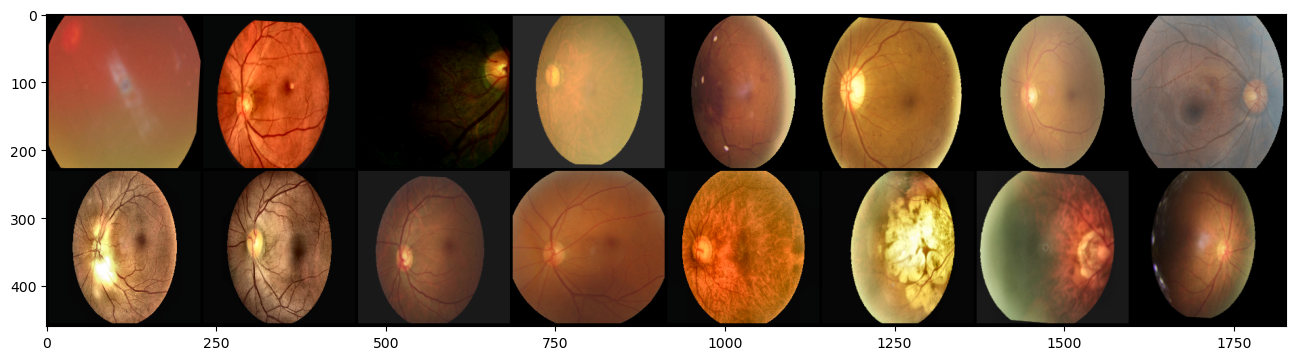

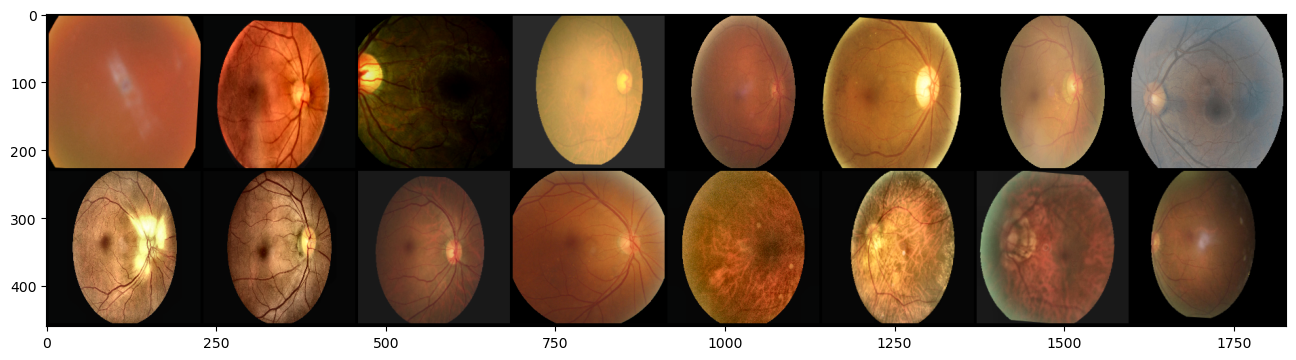

In [12]:
from torch.utils.data.dataloader import DataLoader
import torchvision
import matplotlib.pyplot as plt
plt.figure(figsize=(16,16))
grid_img=torchvision.utils.make_grid(left,8,4)
plt.imshow(grid_img.permute(1, 2, 0))
plt.figure(figsize=(16,16))
grid_img=torchvision.utils.make_grid(right,8,4)
plt.imshow(grid_img.permute(1, 2, 0))

In [13]:
# #test
# model = densenet121()
# x=torch.randn(1,3,224,224)
# l=model(x)
# r=model(x)
# x=torch.cat([l,r],dim=1)
# print(x.shape)
# l=nn.Linear(2000,1000)
# x=l(x)
# x.shape

In [14]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from torchvision.models import densenet121,resnet50
train_df,val_df=train_test_split(train_df,test_size=0.2,random_state=21)

In [15]:
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from torch.utils.data import DataLoader
import timm
import numpy as np
from sklearn import metrics
class OurModel(pl.LightningModule):
    def __init__(self):
        super(OurModel, self).__init__()
        # 模型架构
        self.model = timm.create_model('resnet18d', pretrained=True)
        self.fc1 = nn.Linear(2000, 1000)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(1000, 8)

        # 类别权重计算（基于中位数频率）
        class_counts = train_df.iloc[:, -8:].sum(axis=0).values
        total = len(train_df)
        median = np.median(class_counts)
        self.alpha = torch.tensor([median / (c + 1e-6) for c in class_counts], dtype=torch.float32)
        
        # 训练参数
        self.lr = 1e-3
        self.batch_size = 96
        self.numworker = 8
        self.criterion = nn.BCEWithLogitsLoss(reduction='none')
        self.gamma = 2  # Focal Loss参数

        # 存储测试结果
        self.test_losses = []
        self.test_labels = []
        self.test_preds = []

    def forward(self, xl, xr):
        l = self.model(xl)
        r = self.model(xr)
        x = torch.cat((l, r), 1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

    def focal_loss(self, logits, targets):
        BCE = self.criterion(logits, targets)
        pt = torch.exp(-BCE)  # 防止梯度爆炸
        alpha = self.alpha.to(logits.device).expand_as(targets)
        alpha_factor = torch.where(targets == 1, alpha, 1 - alpha)
        loss = alpha_factor * (1 - pt)**self.gamma * BCE
        return loss.mean()

    def configure_optimizers(self):
        opt = torch.optim.Adam(self.parameters(), lr=self.lr, weight_decay=1e-4)
        scheduler = CosineAnnealingWarmRestarts(opt, T_0=5, T_mult=1, eta_min=1e-5)
        return {'optimizer': opt, 'lr_scheduler': scheduler, 'monitor': 'val_loss'}

    def train_dataloader(self):
        # 加权采样数据加载
        dataset = DataReader(train_df, train_path, aug)
        sample_weights = calculate_sample_weights(train_df)
        sampler = torch.utils.data.WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(dataset),
            replacement=True
        )
        return DataLoader(
            dataset,
            batch_size=self.batch_size,
            sampler=sampler,
            num_workers=self.numworker,
            shuffle=False  # sampler已处理随机性
        )

    def training_step(self, batch, batch_idx):
        left, right, label = batch
        out = self(left, right)
        loss = self.focal_loss(out, label)
        self.log('train_loss', loss, on_epoch=True, prog_bar=True)
        return loss

    def val_dataloader(self):
        return DataLoader(
            DataReader(val_df, train_path, aug),
            batch_size=self.batch_size,
            num_workers=self.numworker,
            shuffle=False
        )

    def validation_step(self, batch, batch_idx):
        left, right, label = batch
        out = self(left, right)
        loss = self.focal_loss(out, label)
        self.log('val_loss', loss, prog_bar=True)
        return loss

    def test_dataloader(self):
        return DataLoader(
            DataReader(test_df, train_path, aug),
            batch_size=self.batch_size,
            num_workers=self.numworker,
            shuffle=False
        )

    def test_step(self, batch, batch_idx):
        left, right, label = batch
        out = self(left, right)
        loss = self.focal_loss(out, label)
        self.test_losses.append(loss)
        self.test_labels.append(label.detach())
        self.test_preds.append(out.detach())
        return {'loss': loss, 'label': label, 'pred': out}

    def on_test_epoch_end(self):
        avg_loss = torch.stack(self.test_losses).mean()
        labels = torch.cat(self.test_labels)
        preds = torch.cat(self.test_preds)

        kappa, f1, auc, final_score, acc = self.ODIR_Metrics(labels, preds)

        self.log('test_loss', avg_loss)
        self.log('kappa', np.round(kappa, 3))
        self.log('f1', np.round(f1, 3))
        self.log('auc', np.round(auc, 3))
        self.log('final_score', np.round(final_score, 3))
        self.log('acc', np.round(acc, 3))

        self.test_losses.clear()
        self.test_labels.clear()
        self.test_preds.clear()

    def ODIR_Metrics(self, gt_data, pr_data):
        th = 0.5
        gt = gt_data.cpu().numpy().flatten()
        pr = pr_data.cpu().numpy().flatten()
        kappa = metrics.cohen_kappa_score(gt, pr > th)
        f1 = metrics.f1_score(gt, pr > th, average='micro')
        auc = metrics.roc_auc_score(gt, pr)
        acc = metrics.accuracy_score(gt, pr > th)
        final_score = (kappa + f1 + auc) / 3.0
        return kappa, f1, auc, final_score, acc

# 需要在类外定义的辅助函数
def calculate_sample_weights(df):
    labels = df.iloc[:, -8:].astype(float).values
    class_counts = labels.sum(axis=0)
    class_weights = 1.0 / (class_counts + 1e-6)
    sample_weights = (labels * class_weights).sum(axis=1)
    sample_weights = sample_weights / sample_weights.sum()
    return torch.from_numpy(sample_weights).float()

In [ ]:
from pytorch_lightning import Trainer
from pytorch_lightning.callbacks import LearningRateMonitor, EarlyStopping, ModelCheckpoint

lr_monitor = LearningRateMonitor(logging_interval='epoch')
early_stop_callback = EarlyStopping(monitor='val_loss', patience=10, verbose=True, mode='min')
checkpoint_callback = ModelCheckpoint(monitor='val_loss', dirpath='./checkpoints', filename='savefile')

model = OurModel()

trainer = Trainer(
    max_epochs=50,
    accelerator="gpu",  # 指定使用 GPU
    devices=-1,  # 使用所有可用的 GPU
    precision=16,  # 使用混合精度训练
    callbacks=[checkpoint_callback, early_stop_callback, lr_monitor]
)


In [ ]:
%%time
trainer.fit(model)
print("finsh")

In [ ]:
trainer.test()

In [ ]:
# submission

In [ ]:
submission_df=pd.read_csv('./ODIR/XYZ_ODIR.csv')
submission_df.head()

In [ ]:
test_path='./ODIR/ODIR-5K_Testing_Images/'

In [ ]:
loader=DataLoader(DataReader(submission_df,test_path,aug), batch_size = model.batch_size,num_workers=model.numworker,shuffle=False)
batch=next(iter(loader))
batch[0].shape,batch[1].shape


In [ ]:
model=model.cuda()
preds=[]
with torch.no_grad():
    model.eval()
    for batch in loader:
        preds.append(model(batch[0].cuda(),batch[1].cuda()))


In [ ]:
preds=torch.cat(preds)
preds.shape


In [ ]:
preds=preds.detach().cpu().numpy()


In [ ]:
preds=np.where(preds>0.5,1,0)#convert probabilities to target


In [ ]:
for i,j in enumerate(submission_df.columns[1::]):
    submission_df[j]=preds[:,i]


In [ ]:
submission_df.head()


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report
)
import torch

class ModelEvaluator:
    def __init__(self, model, val_loader):
        self.model = model.cuda()
        self.val_loader = val_loader
    
    def evaluate(self):
        all_labels = []
        all_preds = []
        with torch.no_grad():
            for batch in self.val_loader:
                left, right, labels = [x.cuda() for x in batch]
                outputs = self.model(left, right)
                all_labels.append(labels.cpu())
                all_preds.append(torch.sigmoid(outputs).cpu())
        
        labels = torch.cat(all_labels).numpy()
        preds = torch.cat(all_preds).numpy()
        binary_preds = (preds > 0.5).astype(int)
        
        # 逐类计算指标
        class_names = ['Class_0', 'Class_1', 'Class_2', 'Class_3',
                      'Class_4', 'Class_5', 'Class_6', 'Class_7']
        
        print("\n=== 逐类性能 ===")
        metrics_dict = {}
        for i in range(8):
            acc = accuracy_score(labels[:, i], binary_preds[:, i])
            pre = precision_score(labels[:, i], binary_preds[:, i], zero_division=0)
            rec = recall_score(labels[:, i], binary_preds[:, i], zero_division=0)
            f1 = f1_score(labels[:, i], binary_preds[:, i], zero_division=0)
            auc = roc_auc_score(labels[:, i], preds[:, i])
            
            metrics_dict[class_names[i]] = {
                'Accuracy': acc,
                'Precision': pre,
                'Recall': rec,
                'F1': f1,
                'AUC': auc
            }
            print(f"\n{class_names[i]}:")
            print(f"Accuracy: {acc:.4f}")
            print(f"Precision: {pre:.4f}")
            print(f"Recall: {rec:.4f}")
            print(f"F1 Score: {f1:.4f}")
            print(f"AUC: {auc:.4f}")
        
        # 总体性能
        print("\n=== 总体性能 ===")
        print(f"Micro F1: {f1_score(labels, binary_preds, average='micro'):.4f}")
        print(f"Macro AUC: {roc_auc_score(labels, preds, average='macro'):.4f}")
        print(f"Cohen Kappa: {cohen_kappa_score(labels, binary_preds):.4f}")
        print("\n分类报告:\n", classification_report(labels, binary_preds, target_names=class_names))
        
        return metrics_dict

# 使用示例
if __name__ == '__main__':
    # 加载模型和数据
    model = OurModel.load_from_checkpoint('/home/coffee_dou/python/ODIR2019-master/more/checkpoints/savefile-v8.ckpt')
    val_loader = DataLoader(DataReader(val_df, train_path, aug), batch_size=32)
    
    # 执行评估
    evaluator = ModelEvaluator(model, val_loader)
    metrics = evaluator.evaluate()

In [ ]:
import torch
import pandas as pd
from torch.utils.data import DataLoader
from pytorch_lightning import Trainer
from pytorch_lightning.callbacks import ModelCheckpoint

# 加载训练好的模型
class InferenceModel:
    def __init__(self, ckpt_path='/home/coffee_dou/python/ODIR2019-master/more/checkpoints/savefile-v8.ckpt'):
        self.model = OurModel.load_from_checkpoint(ckpt_path)
        self.model.eval()
        self.model.cuda()
    
    def predict(self, test_csv='./ODIR/XYZ_ODIR.csv', test_path='./ODIR/ODIR-5K_Testing_Images/'):
        # 加载测试数据
        test_df = pd.read_csv(test_csv)
        test_dataset = DataReader(test_df, test_path, aug)
        test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
        
        # 推理
        preds = []
        with torch.no_grad():
            for batch in test_loader:
                left, right, _ = [x.cuda() for x in batch]
                outputs = self.model(left, right)
                preds.append(torch.sigmoid(outputs).cpu())
        
        # 生成提交文件
        preds = torch.cat(preds).numpy()
        submission = test_df.copy()
        for i, col in enumerate(submission.columns[-8:]):
            submission[col] = (preds[:, i] > 0.).astype(int)
        submission.to_csv('submission.csv', index=False)
        return submission

if __name__ == '__main__':
    infer = InferenceModel()
    results = infer.predict()
    print("推理完成，结果已保存至 submission.csv")